In [ ]:
#THIS NOTEBOOK EVALUATES THE BASELINE MODELS ON THE WYTTENBACH ET AL. 2020 MARKET DRUGS (OUT-OF-DISTRIBUTION TEST). PREDICTIONS WERE MADE BY run_ood.py USING THE 10 NEW BASELINE MODELS PER PROPERTY, THIS NOTEBOOK ONLY READS AND PLOTS

import numpy as np                           #IMPORTS THE NUMERICAL LIBRARY
import pandas as pd                          #IMPORTS THE DATA FRAME HANDLING LIBRARY
import matplotlib.pyplot as plt              #IMPORTS THE PLOTTING LIBRARY
from matplotlib.patches import Patch         #IMPORTS THE LEGEND PATCH TOOL
from rdkit import Chem                       #IMPORTS THE CHEMISTRY LIBRARY
from rdkit.Chem import Descriptors           #IMPORTS THE MOLECULAR DESCRIPTOR TOOLS

KJ_TO_KCAL = 1 / 4.184                       #UNIT CONVERSION, THE PAPER REPORTS kJ/mol

def pick_col(df, metric):                    #FINDS THE TEST-SET COLUMN FOR A METRIC ("mae" OR "rmse") IN A BASELINE SEEDS FILE
    options = [c for c in df.columns if "test" in c.lower() and metric in c.lower() and "ring" not in c.lower()]
    assert len(options) >= 1, f"No test {metric} column found in {df.columns.tolist()}"
    return options[0]

def canonicalize(smi):                       #CANONICAL SMILES WITH STEREOCHEMISTRY REMOVED, SAME AS THE CLEANING PIPELINE
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    Chem.RemoveStereochemistry(mol)
    return Chem.MolToSmiles(mol)

In [2]:
df_wyttenbach = pd.read_csv("RAW DATA/wyttenbach_market_drugs.csv")
if "dHf_kcalmol" not in df_wyttenbach.columns:                                       #CONVERTS kJ/mol TO kcal/mol IF NOT ALREADY DONE
    df_wyttenbach["dHf_kcalmol"] = df_wyttenbach["dHf_kJmol"] * KJ_TO_KCAL

#VALIDATION, SAME CHECKS AS 01_data_validation.ipynb
print("NaN SMILES:", df_wyttenbach["smiles"].isna().sum())
print("NaN Tm:", df_wyttenbach["Tm_K"].isna().sum())
print("NaN dHf:", df_wyttenbach["dHf_kcalmol"].isna().sum())
df_wyttenbach = df_wyttenbach.dropna(subset=["smiles", "Tm_K", "dHf_kcalmol"]).reset_index(drop=True)
df_wyttenbach["smiles"] = df_wyttenbach["smiles"].apply(canonicalize)
print("Unparseable SMILES:", df_wyttenbach["smiles"].isna().sum())
df_wyttenbach = df_wyttenbach.dropna(subset=["smiles"]).reset_index(drop=True)
print(f"Wyttenbach molecules after cleaning: {len(df_wyttenbach)}")                   #SHOULD BE 90

df_wyttenbach["MW"] = df_wyttenbach["smiles"].apply(lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s)))
print(f"Tm range: {df_wyttenbach['Tm_K'].min():.1f} - {df_wyttenbach['Tm_K'].max():.1f} K")
print(f"dHf range: {df_wyttenbach['dHf_kcalmol'].min():.2f} - {df_wyttenbach['dHf_kcalmol'].max():.2f} kcal/mol")
print(f"MW range: {df_wyttenbach['MW'].min():.1f} - {df_wyttenbach['MW'].max():.1f} g/mol")

NaN SMILES: 0
NaN Tm: 0
NaN dHf: 0
Unparseable SMILES: 0
Wyttenbach molecules after cleaning: 90
Tm range: 316.0 - 545.2 K
dHf range: 3.99 - 13.77 kcal/mol
MW range: 121.1 - 705.6 g/mol


In [3]:
#OVERLAP CHECK AGAINST THE CLEAN TRAINING FILES (SHOULD BE 0 FOR BOTH BECAUSE THE WYTTENBACH MOLECULES WERE REMOVED IN 01_data_validation.ipynb)
wyttenbach_set = set(df_wyttenbach["smiles"])
for name, path in [("dHfus", "RAW DATA/dHfus_clean.csv"), ("Tm", "RAW DATA/Tm_clean.csv")]:
    clean_set = set(pd.read_csv(path)["smiles"].apply(canonicalize).dropna())
    n_overlap = len(wyttenbach_set & clean_set)
    print(f"Wyttenbach molecules in {name} clean training data: {n_overlap} / {len(wyttenbach_set)}")

[08:45:47] WARNING: not removing hydrogen atom without neighbors
[08:45:47] WARNING: not removing hydrogen atom without neighbors
[08:45:47] WARNING: not removing hydrogen atom without neighbors
[08:45:47] WARNING: not removing hydrogen atom without neighbors
[08:45:47] WARNING: not removing hydrogen atom without neighbors
[08:45:47] WARNING: not removing hydrogen atom without neighbors
[08:45:47] WARNING: not removing hydrogen atom without neighbors
[08:45:47] Unusual charge on atom 6 number of radical electrons set to zero


Wyttenbach molecules in dHfus clean training data: 0 / 90
Wyttenbach molecules in Tm clean training data: 0 / 90


[08:45:50] WARNING: not removing hydrogen atom without neighbors
[08:45:50] WARNING: not removing hydrogen atom without neighbors
[08:45:50] WARNING: not removing hydrogen atom without neighbors
[08:45:50] WARNING: not removing hydrogen atom without neighbors
[08:45:50] WARNING: not removing hydrogen atom without neighbors
[08:45:50] WARNING: not removing hydrogen atom without neighbors
[08:45:50] WARNING: not removing hydrogen atom without neighbors
[08:45:50] Unusual charge on atom 6 number of radical electrons set to zero


dHfus training median MW: 213.2 | Wyttenbach median MW: 314.3
Tm training median MW: 320.4 | Wyttenbach median MW: 314.3


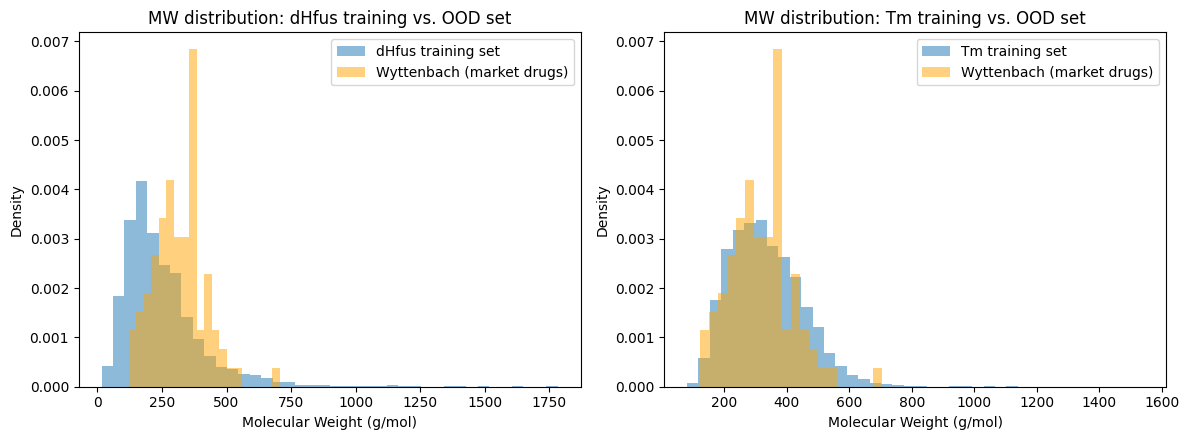

In [4]:
#MW DISTRIBUTION: TRAINING DATA VS. WYTTENBACH (BOTH PROPERTIES)
train_files = {"dHfus": "dHfus_baseline_train_predictions.csv", "Tm": "Tm_baseline_train_predictions.csv"}     #SEED 0 TRAINING SETS
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, path) in zip(axes, train_files.items()):
    train_df = pd.read_csv(path)
    train_mw = train_df["smiles"].apply(lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s)))
    ax.hist(train_mw, bins=40, alpha=0.5, density=True, label=f"{name} training set")
    ax.hist(df_wyttenbach["MW"], bins=20, alpha=0.5, density=True, color="orange", label="Wyttenbach (market drugs)")
    ax.set_xlabel("Molecular Weight (g/mol)")
    ax.set_ylabel("Density")
    ax.set_title(f"MW distribution: {name} training vs. OOD set")
    ax.legend()
    print(f"{name} training median MW: {train_mw.median():.1f} | Wyttenbach median MW: {df_wyttenbach['MW'].median():.1f}")
plt.tight_layout()
plt.savefig("plots_wyttenbach_MW_vs_training.png", dpi=150)
plt.show()

In [5]:
#LOAD THE OOD RESULTS WRITTEN BY run_ood.py
ood = {}
for name in ["dHfus", "Tm"]:
    ood[name] = dict(
        seeds=pd.read_csv(f"ood_seeds_{name}.csv"),                       #PER-SEED OOD MAE AND RMSE, PLUS JOBACK
        seed0=pd.read_csv(f"{name}_ood_predictions.csv"),                 #SEED 0 PER-MOLECULE PREDICTIONS
        ens=pd.read_csv(f"{name}_ood_ensemble.csv"),                      #MEAN PREDICTION OVER SEEDS PLUS JOBACK PER MOLECULE
        base=pd.read_csv(f"baseline_seeds_{name}.csv"),                   #IN-DISTRIBUTION BASELINE RESULTS PER SEED
    )
    s = ood[name]["seeds"]
    e = ood[name]["ens"]["abs_error_mean_pred"]
    print(f"{name}: OOD over {len(s)} seeds: MAE {s['ood_mae'].mean():.3f} ± {s['ood_mae'].std():.3f}, RMSE {s['ood_rmse'].mean():.3f} ± {s['ood_rmse'].std():.3f}")
    print(f"{name}: ensemble of seeds:  MAE {e.mean():.3f}, RMSE {np.sqrt((e**2).mean()):.3f}")
    print(f"{name}: Joback (own, same drugs): MAE {s['joback_mae'].iloc[0]:.3f}, RMSE {s['joback_rmse'].iloc[0]:.3f} (valid {int(s['n_joback_valid'].iloc[0])} / {int(s['n'].iloc[0])})")

dHfus: OOD over 10 seeds: MAE 1.359 ± 0.150, RMSE 1.847 ± 0.246
dHfus: ensemble of seeds:  MAE 1.246, RMSE 1.718
dHfus: Joback (own, same drugs): MAE 2.190, RMSE 2.838 (valid 89 / 90)
Tm: OOD over 10 seeds: MAE 25.079 ± 1.403, RMSE 31.463 ± 1.254
Tm: ensemble of seeds:  MAE 23.780, RMSE 29.947
Tm: Joback (own, same drugs): MAE 177.917, RMSE 219.331 (valid 89 / 90)


In [6]:
#LITERATURE BENCHMARKS FROM WYTTENBACH ET AL. 2020 (SAME 90 DRUGS), kJ/mol CONVERTED TO kcal/mol
paper_benchmarks = pd.DataFrame({
    "Method": ["Joback & Reid (paper)", "COSMOquick (paper)"],
    "Tm_RMSE_K": [204.01, 22.43],
    "dHf_RMSE_kcalmol": [10.52 * KJ_TO_KCAL, 6.63 * KJ_TO_KCAL],
})
print(paper_benchmarks.round(2).to_string(index=False))

#SUMMARY TABLE: BASELINE MODEL VS. JOBACK (OWN) VS. LITERATURE, RMSE ON THE WYTTENBACH SET
summary_rows = []
for name, bench_col, unit in [("dHfus", "dHf_RMSE_kcalmol", "kcal/mol"), ("Tm", "Tm_RMSE_K", "K")]:
    s = ood[name]["seeds"]
    summary_rows += [
        dict(Property=name, Unit=unit, Method="Baseline model (mean ± std, 10 seeds)", RMSE=s["ood_rmse"].mean(), RMSE_std=s["ood_rmse"].std(), MAE=s["ood_mae"].mean(), MAE_std=s["ood_mae"].std()),
        dict(Property=name, Unit=unit, Method="Joback (own implementation)", RMSE=s["joback_rmse"].iloc[0], RMSE_std=np.nan, MAE=s["joback_mae"].iloc[0], MAE_std=np.nan),
        dict(Property=name, Unit=unit, Method="Joback & Reid (paper)", RMSE=paper_benchmarks.loc[0, bench_col], RMSE_std=np.nan, MAE=np.nan, MAE_std=np.nan),
        dict(Property=name, Unit=unit, Method="COSMOquick (paper)", RMSE=paper_benchmarks.loc[1, bench_col], RMSE_std=np.nan, MAE=np.nan, MAE_std=np.nan),
    ]
ood_summary = pd.DataFrame(summary_rows)
print(ood_summary.round(3).to_string(index=False))
ood_summary.to_csv("ood_summary_table.csv", index=False)

               Method  Tm_RMSE_K  dHf_RMSE_kcalmol
Joback & Reid (paper)     204.01              2.51
   COSMOquick (paper)      22.43              1.58
Property     Unit                                Method    RMSE  RMSE_std     MAE  MAE_std
   dHfus kcal/mol Baseline model (mean ± std, 10 seeds)   1.847     0.246   1.359    0.150
   dHfus kcal/mol           Joback (own implementation)   2.838       NaN   2.190      NaN
   dHfus kcal/mol                 Joback & Reid (paper)   2.514       NaN     NaN      NaN
   dHfus kcal/mol                    COSMOquick (paper)   1.585       NaN     NaN      NaN
      Tm        K Baseline model (mean ± std, 10 seeds)  31.463     1.254  25.079    1.403
      Tm        K           Joback (own implementation) 219.331       NaN 177.917      NaN
      Tm        K                 Joback & Reid (paper) 204.010       NaN     NaN      NaN
      Tm        K                    COSMOquick (paper)  22.430       NaN     NaN      NaN


In [7]:
#PLOTTING FUNCTIONS (USED FOR BOTH PROPERTIES)
def parity_with_bands(df, bands, unit, label, title_prop, fname):
    fig, ax = plt.subplots(figsize=(7.5, 7.5))
    max_val = max(df["y_true"].max(), df["y_pred"].max()) * 1.05
    x_line = np.linspace(0, max_val, 200)
    for lo, hi, color in bands:                                          #SAME BAND WIDTHS AS THE BASELINE PARITY PLOTS
        ax.fill_between(x_line, x_line + lo, x_line + hi, color=color, alpha=0.6, linewidth=0)
        ax.fill_between(x_line, np.maximum(x_line - hi, 0), np.maximum(x_line - lo, 0), color=color, alpha=0.6, linewidth=0)
    ax.plot(x_line, x_line, "k--", linewidth=1.2, zorder=5)
    ax.scatter(df["y_true"], df["y_pred"], color="black", s=30, alpha=0.8, zorder=6, edgecolor="none")
    legend_elements = [Patch(facecolor=c, alpha=0.6, label=f"±{lo}-{hi} {unit}") for lo, hi, c in bands]
    legend_elements.append(plt.Line2D([0], [0], color="black", linestyle="--", label="y = x"))
    ax.legend(handles=legend_elements, loc="upper left", fontsize=8)
    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)
    rmse = np.sqrt((df["abs_error"] ** 2).mean())
    ax.set_xlabel(f"True {title_prop} ({unit}), Wyttenbach market drugs")
    ax.set_ylabel(f"Predicted {title_prop} ({unit})")
    ax.set_title(f"OOD parity plot, {title_prop} ({label})\nMAE={df['abs_error'].mean():.3f}, RMSE={rmse:.3f} {unit}")
    ax.set_aspect("equal", adjustable="box")
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

def cumulative_error(df, thresholds, unit, title_prop, fname):
    errs = np.sort(df["abs_error"].values)
    frac = np.arange(1, len(errs) + 1) / len(errs)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(errs, frac, linewidth=2)
    for th in thresholds:
        within = (df["abs_error"] <= th).mean()
        ax.axvline(th, color="gray", linestyle=":", alpha=0.6)
        ax.annotate(f"{within:.0%} within {th} {unit}", xy=(th, within), xytext=(th + 0.02 * errs.max(), within - 0.08), fontsize=8)
    ax.set_xlabel(f"Absolute error threshold ({unit})")
    ax.set_ylabel("Fraction of OOD set within threshold")
    ax.set_title(f"Cumulative error distribution, {title_prop}, Wyttenbach OOD")
    ax.set_xlim(0, errs.max())
    ax.set_ylim(0, 1.02)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

def band_table(df, edges, labels, fname):
    banded = pd.cut(df["abs_error"], bins=edges, labels=labels, right=True)
    counts = banded.value_counts().reindex(labels)
    pct = counts / len(df) * 100
    table = pd.DataFrame({"Band": labels, "Count": counts.values, "Percentage": pct.round(1).values, "Cumulative %": pct.cumsum().round(1).values})
    print(table.to_string(index=False))
    table.to_csv(fname, index=False)

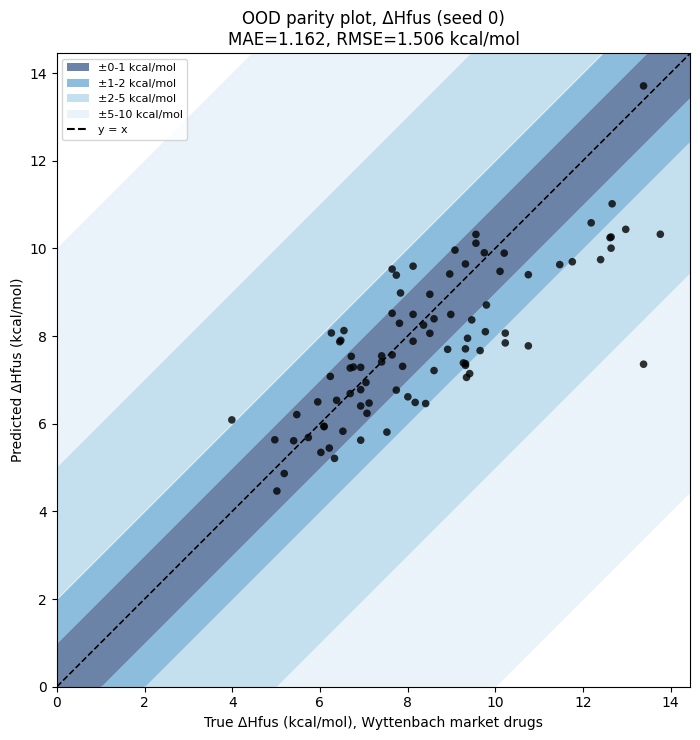

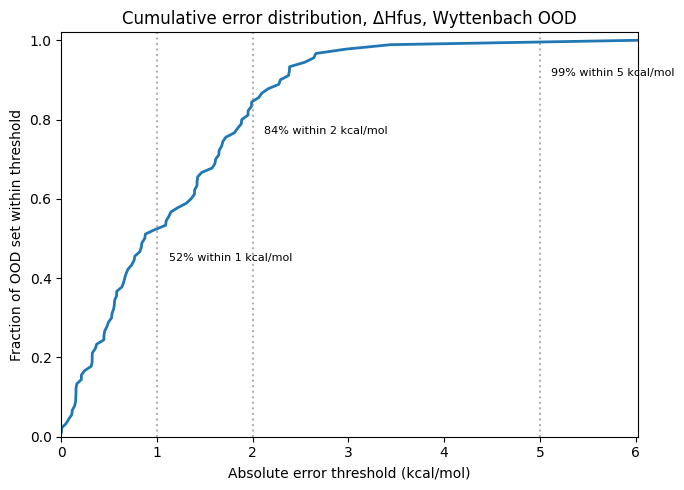

Band  Count  Percentage  Cumulative %
 0-1     47        52.2          52.2
 1-2     29        32.2          84.4
 2-5     13        14.4          98.9
5-10      1         1.1         100.0
 >10      0         0.0         100.0


In [8]:
#dHfus OOD: PARITY PLOT, CUMULATIVE ERROR CURVE AND ERROR BAND TABLE (SEED 0 MODEL)
bands_dhfus = [(0, 1, "#08306b"), (1, 2, "#4292c6"), (2, 5, "#9ecae1"), (5, 10, "#deebf7")]
parity_with_bands(ood["dHfus"]["seed0"], bands_dhfus, "kcal/mol", "seed 0", "ΔHfus", "plots_wyttenbach_dHfus_parity_bands.png")
cumulative_error(ood["dHfus"]["seed0"], [1, 2, 5], "kcal/mol", "ΔHfus", "plots_wyttenbach_dHfus_cumulative_error.png")
band_table(ood["dHfus"]["seed0"], [0, 1, 2, 5, 10, np.inf], ["0-1", "1-2", "2-5", "5-10", ">10"], "dHfus_ood_error_bands.csv")

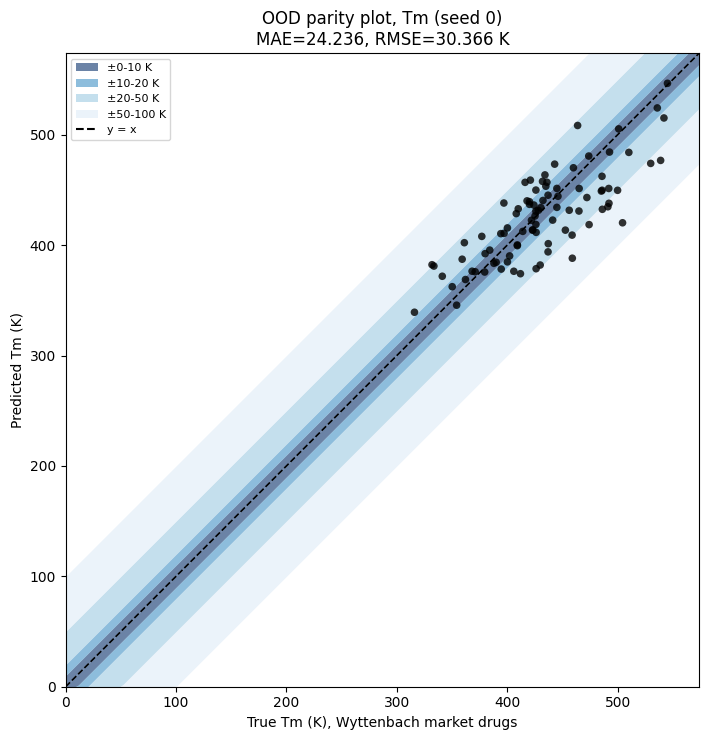

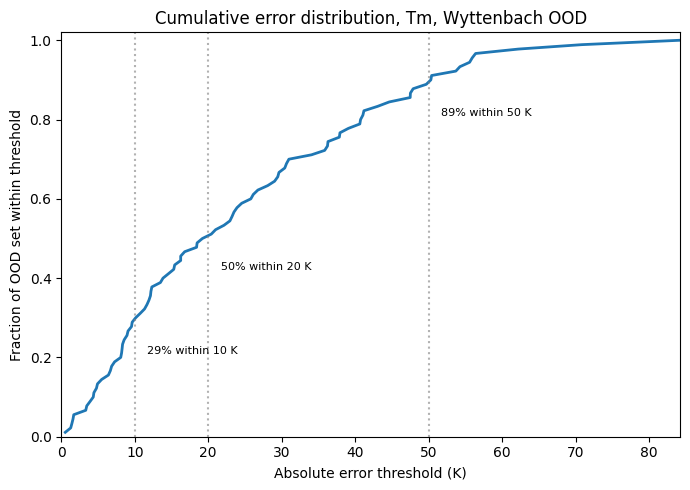

  Band  Count  Percentage  Cumulative %
  0-10     26        28.9          28.9
 10-20     19        21.1          50.0
 20-50     35        38.9          88.9
50-100     10        11.1         100.0
  >100      0         0.0         100.0


In [9]:
#Tm OOD: PARITY PLOT, CUMULATIVE ERROR CURVE AND ERROR BAND TABLE (SEED 0 MODEL)
bands_tm = [(0, 10, "#08306b"), (10, 20, "#4292c6"), (20, 50, "#9ecae1"), (50, 100, "#deebf7")]
parity_with_bands(ood["Tm"]["seed0"], bands_tm, "K", "seed 0", "Tm", "plots_wyttenbach_Tm_parity_bands.png")
cumulative_error(ood["Tm"]["seed0"], [10, 20, 50], "K", "Tm", "plots_wyttenbach_Tm_cumulative_error.png")
band_table(ood["Tm"]["seed0"], [0, 10, 20, 50, 100, np.inf], ["0-10", "10-20", "20-50", "50-100", ">100"], "Tm_ood_error_bands.csv")

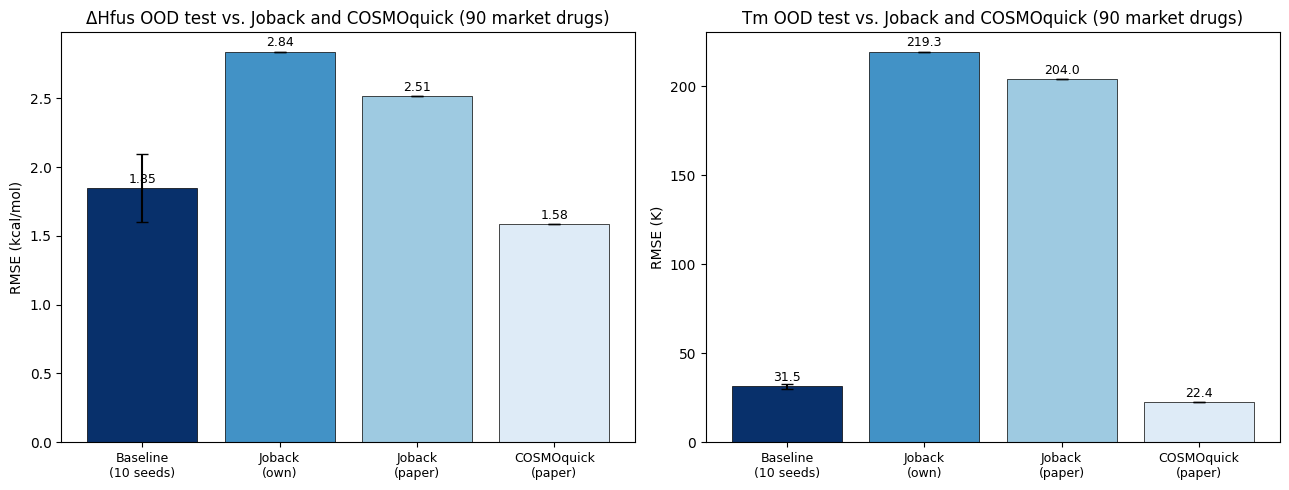

In [10]:
#METHOD COMPARISON: RMSE OF THE BASELINE MODEL VS. JOBACK (OWN AND PAPER) VS. COSMOquick, ON THE SAME 90 DRUGS
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ["#08306b", "#4292c6", "#9ecae1", "#deebf7"]
for ax, name, unit in zip(axes, ["dHfus", "Tm"], ["kcal/mol", "K"]):
    sub = ood_summary[ood_summary["Property"] == name].reset_index(drop=True)
    errs = sub["RMSE_std"].fillna(0).values
    bars = ax.bar(sub["Method"], sub["RMSE"], yerr=errs, capsize=4, color=colors, edgecolor="black", linewidth=0.5)
    for bar, v in zip(bars, sub["RMSE"]):
        ax.annotate(f"{v:.1f}" if name == "Tm" else f"{v:.2f}", xy=(bar.get_x() + bar.get_width() / 2, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.set_ylabel(f"RMSE ({unit})")
    ax.set_title(f"{'ΔHfus' if name == 'dHfus' else 'Tm'} OOD test vs. Joback and COSMOquick (90 market drugs)")
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(["Baseline\n(10 seeds)", "Joback\n(own)", "Joback\n(paper)", "COSMOquick\n(paper)"], fontsize=9)
plt.tight_layout()
plt.savefig("plots_wyttenbach_method_comparison.png", dpi=150)
plt.show()

dHfus: MAE 1.816 (ID) -> 1.359 (OOD), -25.2% | RMSE 3.359 -> 1.847, -45.0%
Tm: MAE 32.665 (ID) -> 25.079 (OOD), -23.2% | RMSE 42.633 -> 31.463, -26.2%


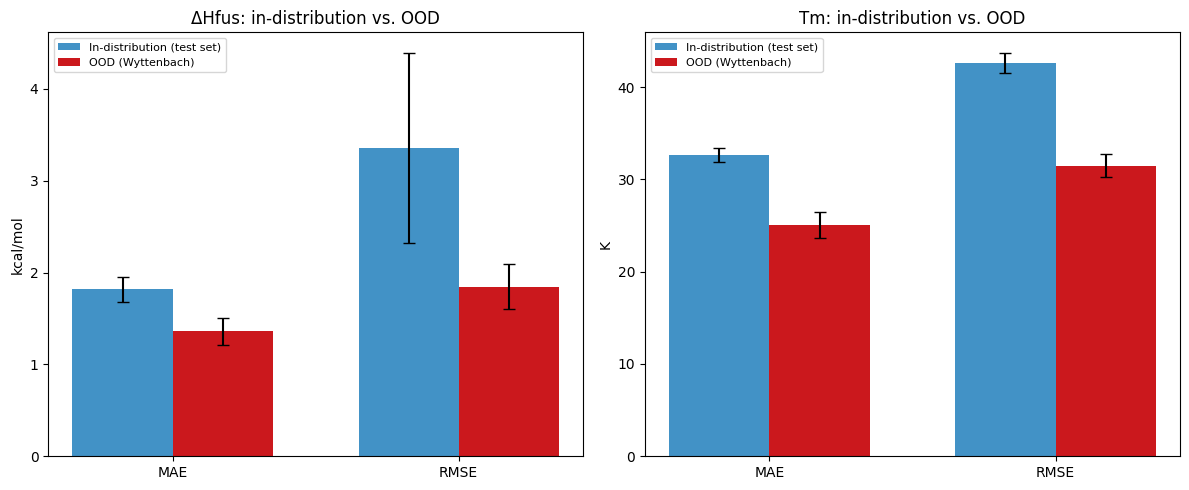

In [11]:
#IN-DISTRIBUTION VS. OUT-OF-DISTRIBUTION (MEAN ± STD OVER 10 SEEDS). MAE IS THE MORE ROBUST METRIC, THE dHfus RMSE IS DOMINATED BY A FEW LARGE OUTLIERS
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, unit in zip(axes, ["dHfus", "Tm"], ["kcal/mol", "K"]):
    b = ood[name]["base"]
    s = ood[name]["seeds"]
    id_mae, id_rmse = b[pick_col(b, "mae")], b[pick_col(b, "rmse")]
    x = np.arange(2)
    width = 0.35
    ax.bar(x - width / 2, [id_mae.mean(), id_rmse.mean()], width, yerr=[id_mae.std(), id_rmse.std()], capsize=4, color="#4292c6", label="In-distribution (test set)")
    ax.bar(x + width / 2, [s["ood_mae"].mean(), s["ood_rmse"].mean()], width, yerr=[s["ood_mae"].std(), s["ood_rmse"].std()], capsize=4, color="#cb181d", label="OOD (Wyttenbach)")
    ax.set_xticks(x)
    ax.set_xticklabels(["MAE", "RMSE"])
    ax.set_ylabel(unit)
    ax.set_title(f"{'ΔHfus' if name == 'dHfus' else 'Tm'}: in-distribution vs. OOD")
    ax.legend(fontsize=8)
    print(f"{name}: MAE {id_mae.mean():.3f} (ID) -> {s['ood_mae'].mean():.3f} (OOD), {(s['ood_mae'].mean() / id_mae.mean() - 1) * 100:+.1f}% | RMSE {id_rmse.mean():.3f} -> {s['ood_rmse'].mean():.3f}, {(s['ood_rmse'].mean() / id_rmse.mean() - 1) * 100:+.1f}%")
plt.tight_layout()
plt.savefig("plots_wyttenbach_id_vs_ood.png", dpi=150)
plt.show()

In [12]:
#DOES THE MODEL BEAT JOBACK ON THE SAME DRUGS? PAIRED BOOTSTRAP OF THE MEAN ABSOLUTE ERROR DIFFERENCE (JOBACK MINUS MODEL). MODEL ERROR PER DRUG = AVERAGE OVER THE 10 SEEDS' INDIVIDUAL ERRORS (A SINGLE-MODEL ERROR, NOT THE ENSEMBLE)
rng = np.random.default_rng(0)
for name, unit in [("dHfus", "kcal/mol"), ("Tm", "K")]:
    seed_errors = np.vstack([pd.read_csv(f"{name}_ood_predictions_s{k}.csv")["abs_error"].values for k in range(10)])
    comp = pd.DataFrame({"model_abs_error": seed_errors.mean(axis=0),
                         "joback_abs_error": ood[name]["ens"]["joback_abs_error"].values}).dropna()       #SAME DRUG ORDER IN BOTH FILES, DROPS DRUGS WHERE JOBACK FAILED
    diff = (comp["joback_abs_error"] - comp["model_abs_error"]).values
    boots = [rng.choice(diff, len(diff), replace=True).mean() for _ in range(5000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f"{name}: n={len(comp)} drugs with a valid Joback value")
    print(f"  Model MAE {comp['model_abs_error'].mean():.2f} {unit}, Joback MAE {comp['joback_abs_error'].mean():.2f} {unit}")
    print(f"  Model advantage (MAE) {diff.mean():.2f} {unit}, 95% CI {lo:.2f} to {hi:.2f}")
    print(f"  Model closer than Joback for {(diff > 0).mean():.0%} of drugs")
    

dHfus: n=89 drugs with a valid Joback value
  Model MAE 1.36 kcal/mol, Joback MAE 2.19 kcal/mol
  Model advantage (MAE) 0.83 kcal/mol, 95% CI 0.43 to 1.24
  Model closer than Joback for 65% of drugs
Tm: n=89 drugs with a valid Joback value
  Model MAE 25.23 K, Joback MAE 177.92 K
  Model advantage (MAE) 152.68 K, 95% CI 127.29 to 180.18
  Model closer than Joback for 94% of drugs


In [13]:
#RELATIVE ERROR TABLE: MEDIAN ABSOLUTE PERCENTAGE ERROR (MdAPE) AND SHARE OF DRUGS WITHIN 10% AND 20% OF THE TRUE VALUE. MEDIAN, NOT MEAN, BECAUSE THE MEAN IS DOMINATED BY MOLECULES WITH SMALL TRUE VALUES (ESPECIALLY dHfus)
#MODEL ROWS USE THE SEED 0 MODEL. THE JOBACK ROW USES THE SAME DRUGS (ONLY THOSE WHERE JOBACK GAVE A VALUE)
def rel_stats(true, abs_err):
    pct = abs_err / np.abs(true) * 100                                    #ABSOLUTE PERCENTAGE ERROR PER MOLECULE
    return pct.median(), (pct <= 10).mean() * 100, (pct <= 20).mean() * 100

rows = []
for name in ["dHfus", "Tm"]:
    id_df = pd.read_csv(f"{name}_baseline_predictions.csv")               #SEED 0 IN-DISTRIBUTION TEST SET
    ood_df = ood[name]["seed0"]                                           #SEED 0 OOD PREDICTIONS
    jo_df = ood[name]["ens"].dropna(subset=["joback_abs_error"])          #JOBACK ON THE WYTTENBACH DRUGS
    for label, true, err in [("Baseline, in-distribution test set (seed 0)", id_df["y_true"], id_df["abs_error"]),
                             ("Baseline, Wyttenbach OOD (seed 0)", ood_df["y_true"], ood_df["abs_error"]),
                             ("Joback (own), Wyttenbach OOD", jo_df["y_true"], jo_df["joback_abs_error"])]:
        md, w10, w20 = rel_stats(true, err)
        rows.append({"Property": name, "Setting": label, "n": len(true), "Median APE (%)": md, "Within 10% (%)": w10, "Within 20% (%)": w20})
relative_table = pd.DataFrame(rows)
print(relative_table.round(1).to_string(index=False))
relative_table.to_csv("ood_relative_error_table.csv", index=False)

Property                                     Setting    n  Median APE (%)  Within 10% (%)  Within 20% (%)
   dHfus Baseline, in-distribution test set (seed 0)  450            19.1            28.4            53.1
   dHfus           Baseline, Wyttenbach OOD (seed 0)   90            12.5            40.0            74.4
   dHfus                Joback (own), Wyttenbach OOD   89            22.4            30.3            46.1
      Tm Baseline, in-distribution test set (seed 0) 1000             5.7            71.9            94.8
      Tm           Baseline, Wyttenbach OOD (seed 0)   90             4.7            82.2           100.0
      Tm                Joback (own), Wyttenbach OOD   89            36.3            14.6            27.0
